# K-means et LDA - version 2

Ce notebook realise le preprocessing, la LDA et le K-means sur les cinq descripteurs selectionnes.

Pour les descripteurs finissant par `_Asymmetry`, les valeurs nulles sont d'abord clusterisees avec le descripteur correspondant finissant par `_Mean`. Le K-means principal est ensuite applique uniquement aux valeurs non nulles.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

random_state = 42
n_init = 20

## Chargement et preprocessing

In [2]:
X_train = pd.read_csv('Données/X_train_clean.csv')
y_train = pd.read_csv('Données/Y_train_clean.csv')

print(f'Shape de X_train : {X_train.shape}')
print(f'Valeurs manquantes : {X_train.isna().sum().sum()}')

num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns
X_num = X_train[num_cols]

numeric_cols = X_num.columns.tolist()
print(f"Colonnes numériques : {numeric_cols}")

Shape de X_train : (444, 34)
Valeurs manquantes : 0
Colonnes numériques : ['Family_Size', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance', 'TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean', 'Pfam_Asymmetry', 'Pfam_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match', 'Expression_Data_Missing']


### Distribution variables 

Variables catégorielles (12) : ['TE_Env_Pair_TE-free_TE-free', 'TE_Env_Pair_TE-free_TE-poor', 'TE_Env_Pair_TE-free_TE-rich', 'TE_Env_Pair_TE-poor_TE-poor', 'TE_Env_Pair_TE-poor_TE-rich', 'TE_Env_Pair_TE-rich_TE-rich', 'TE_Env_Class_free', 'TE_Env_Class_half', 'TE_Env_Class_rich', 'Pfam_Asymmetry', 'TE_Env_Match', 'Expression_Data_Missing']
Variables continues (22) : ['Family_Size', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance', 'TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean', 'Pfam_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean']


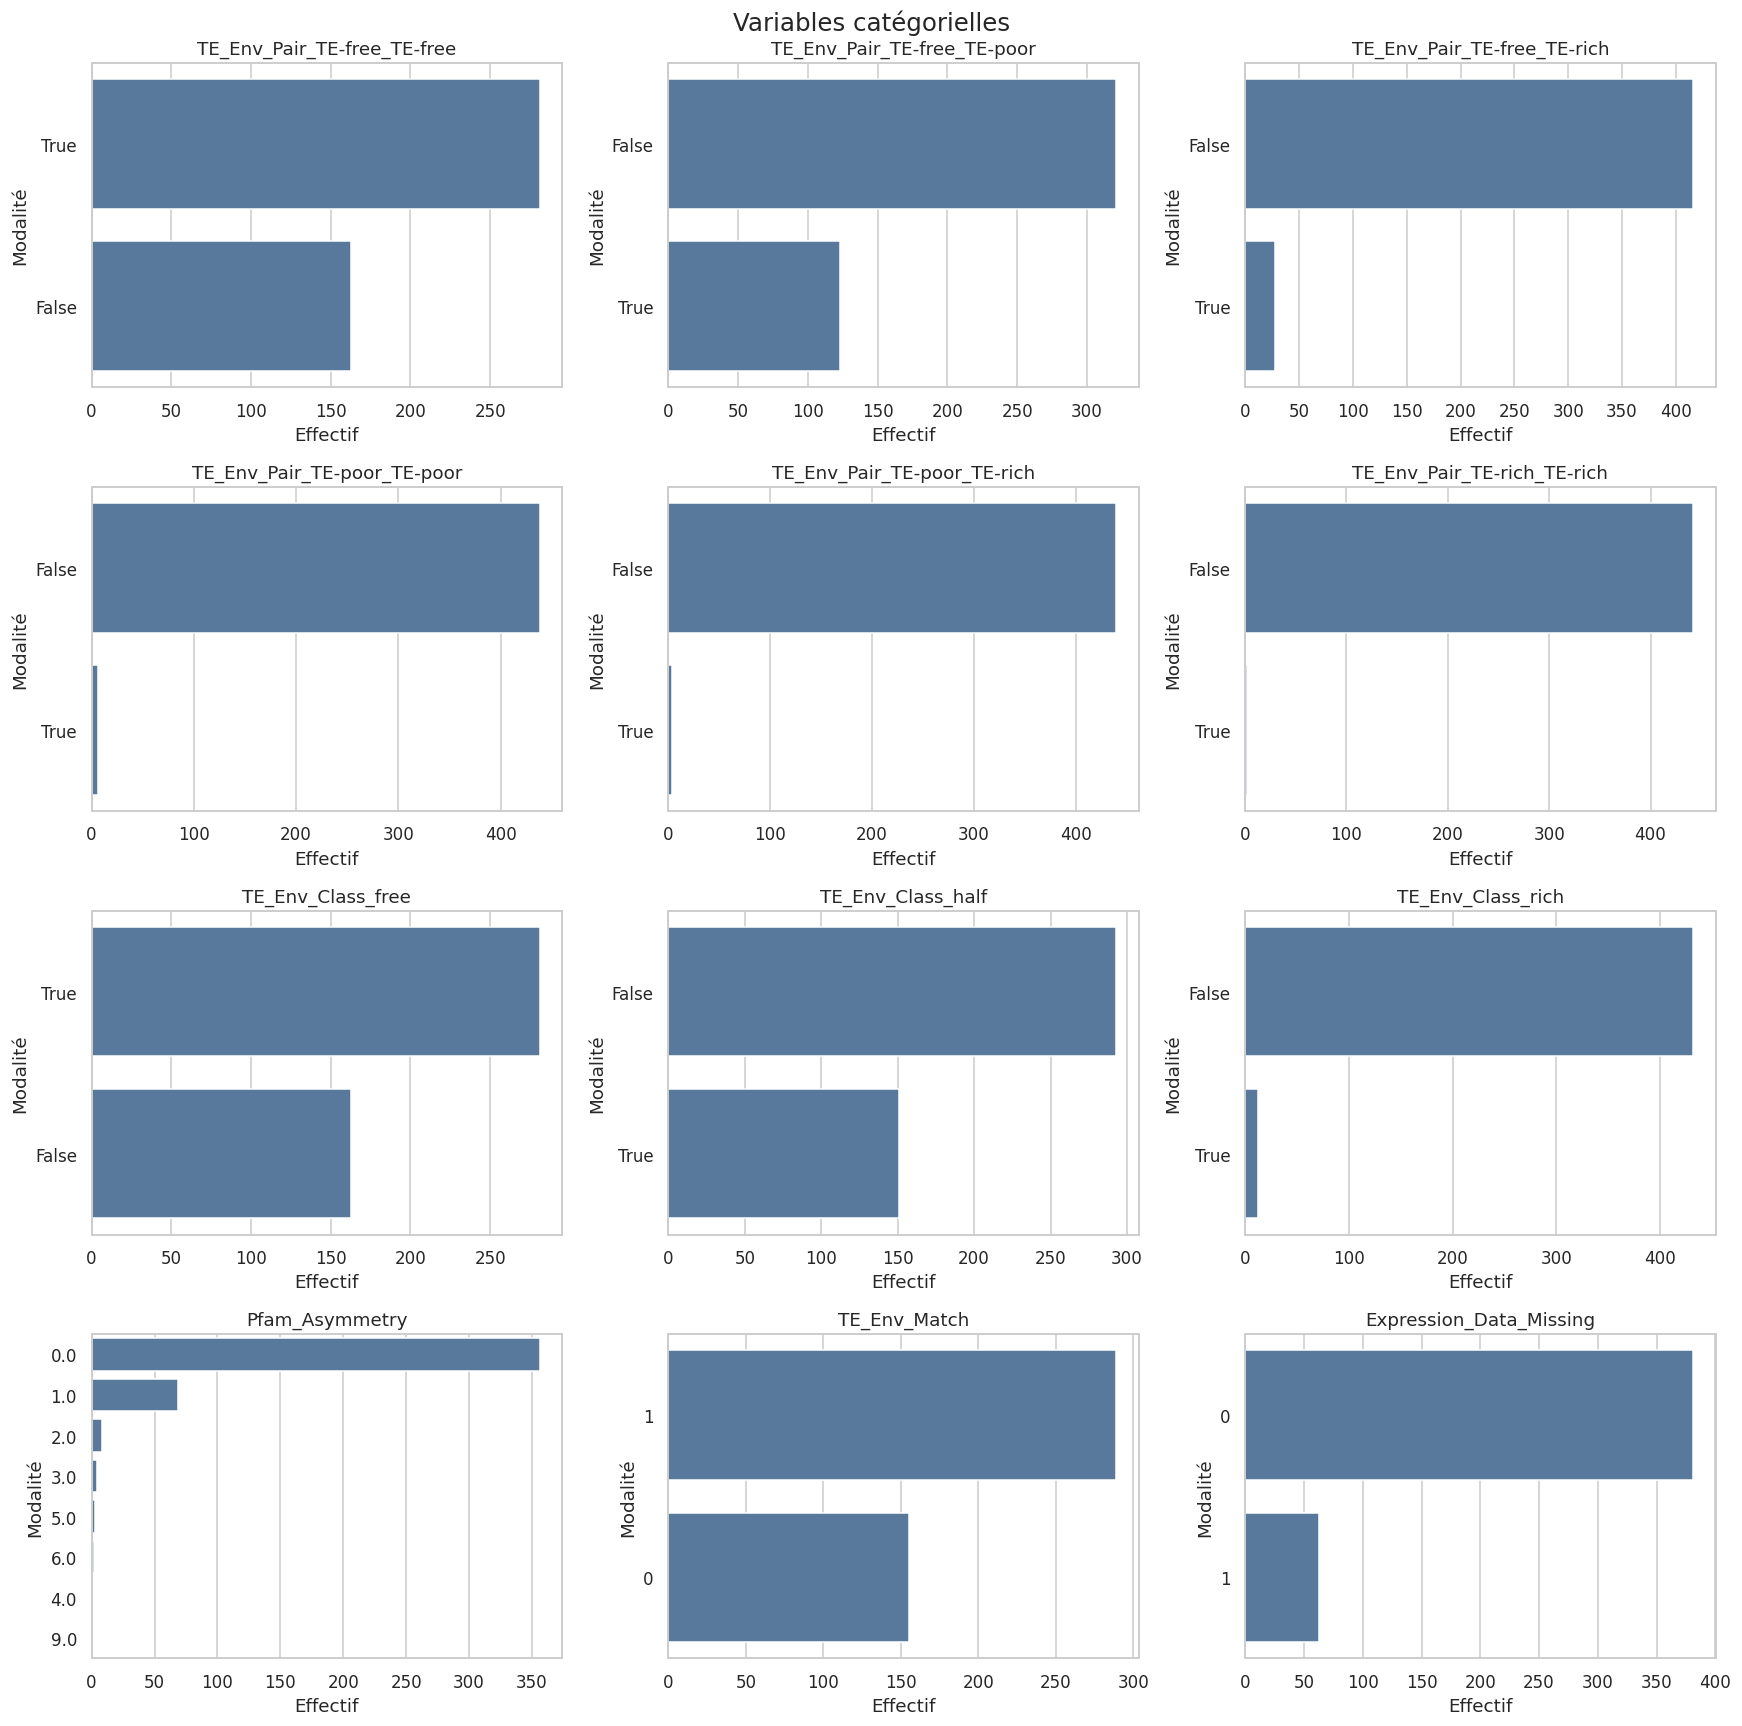

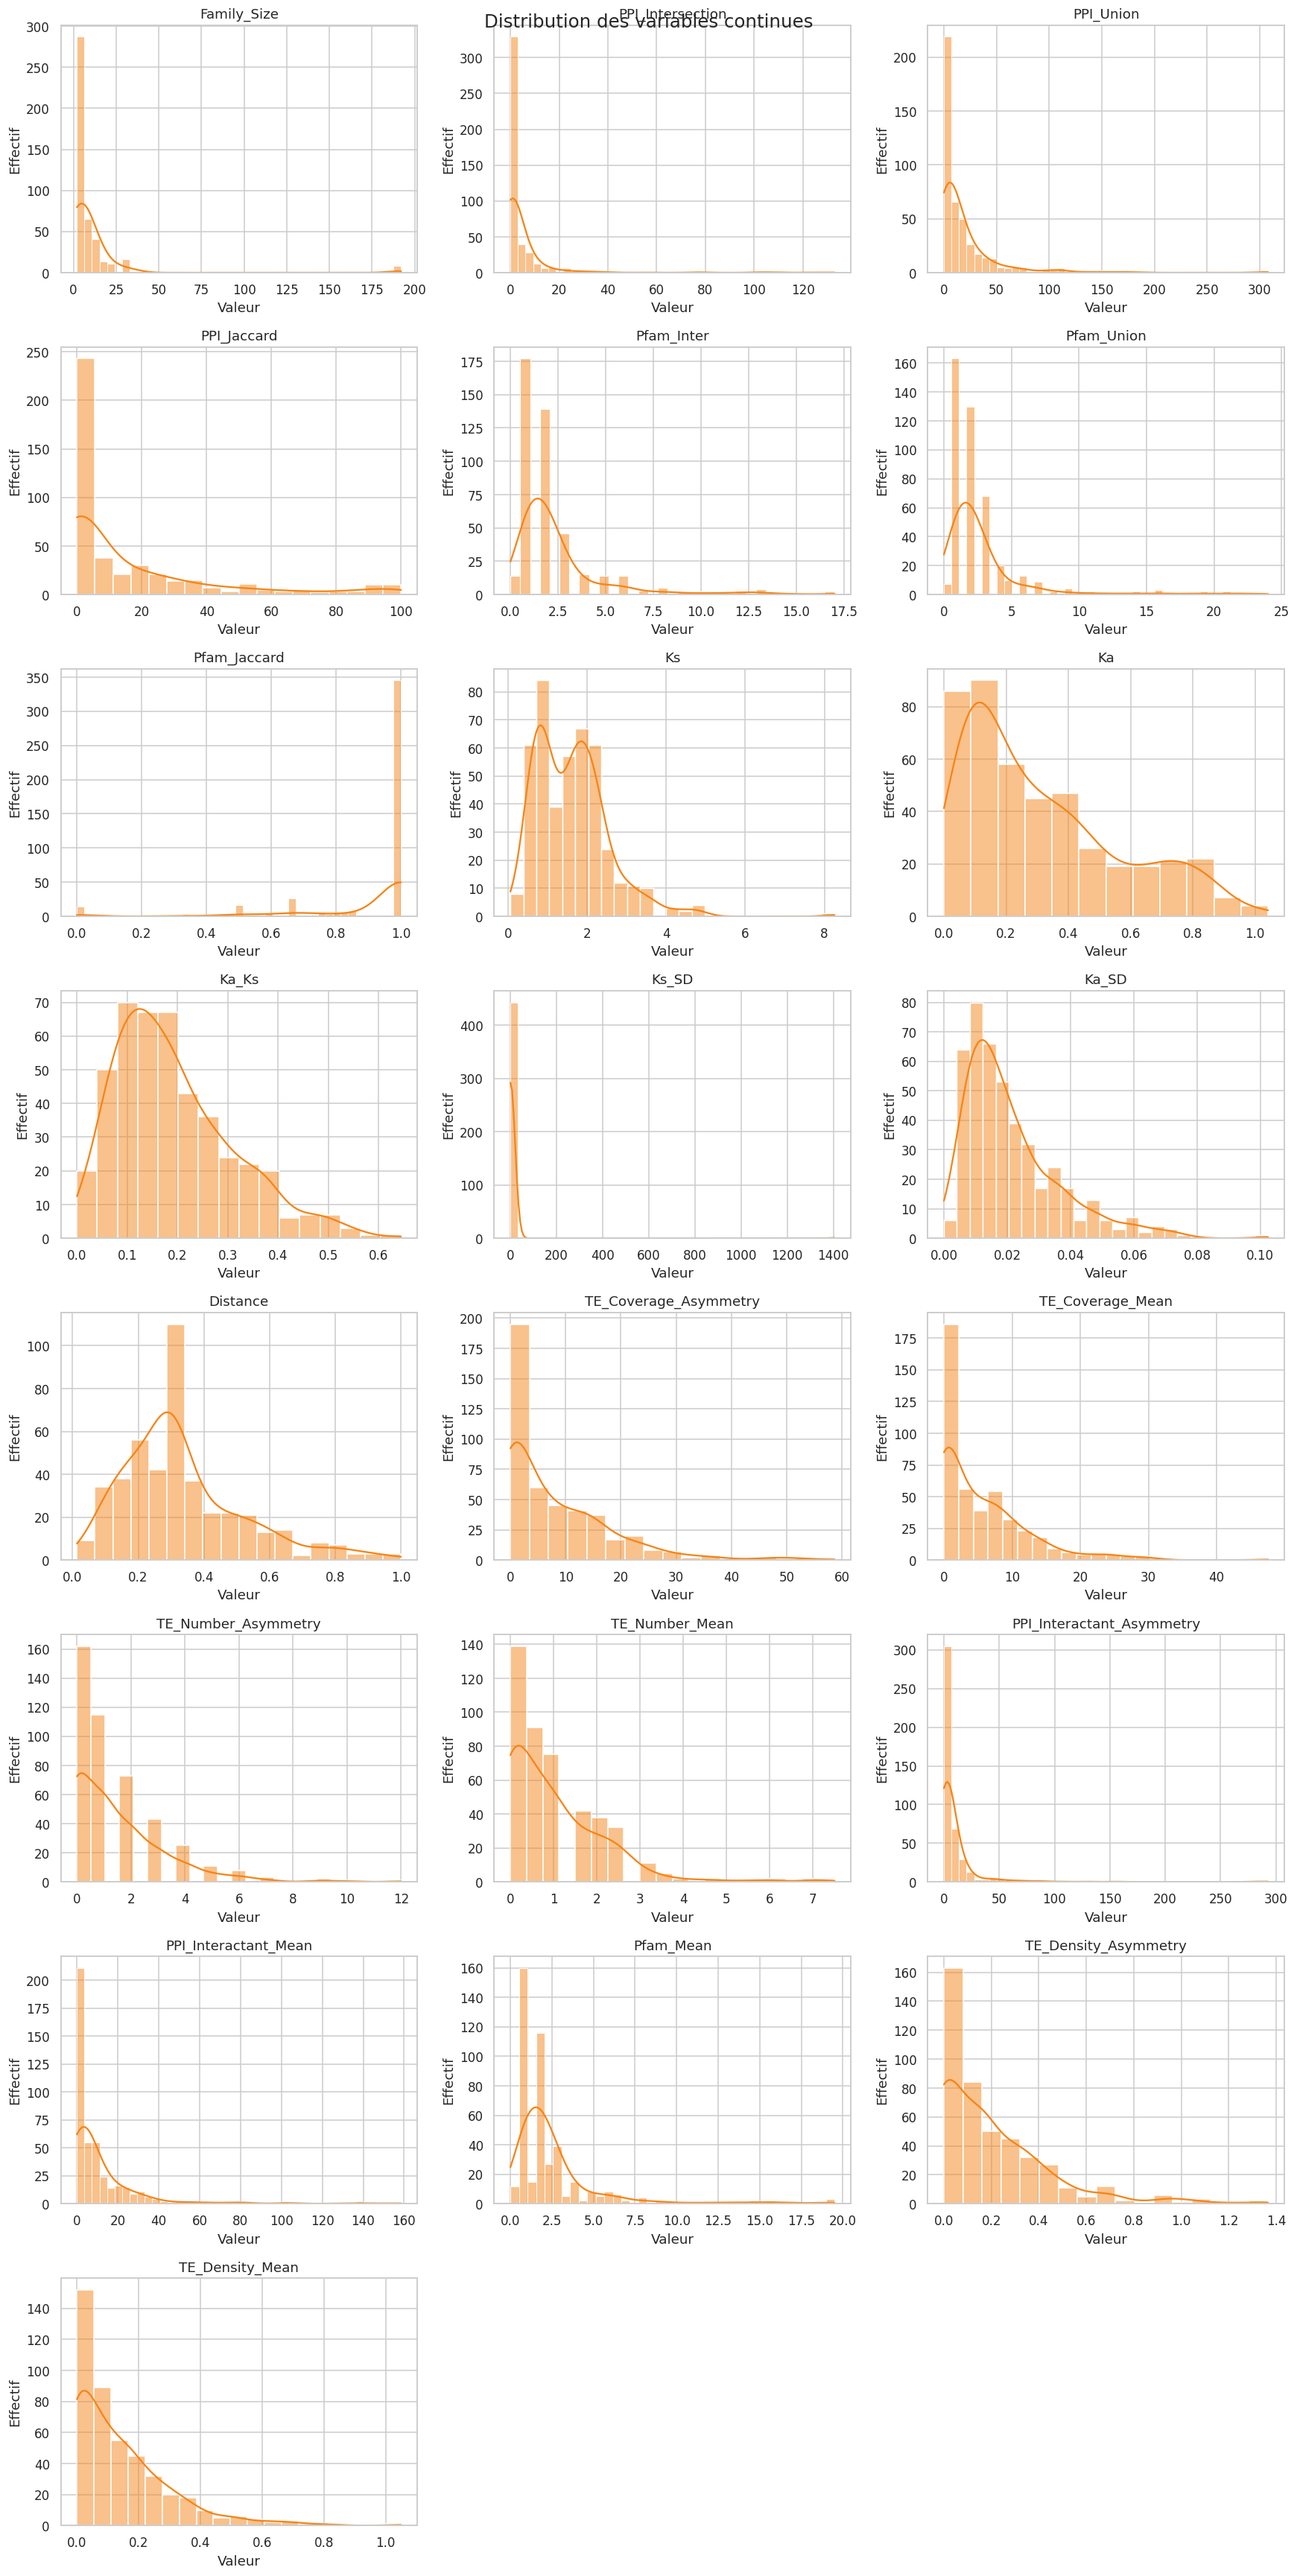

In [3]:
# Distribution des variables catégorielles et continues de X_train
max_categories = 10
categorical_cols = X_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
encoded_categorical_cols = [
    column for column in numeric_cols
    if X_train[column].nunique(dropna=True) <= max_categories
]
categorical_cols = list(dict.fromkeys(categorical_cols + encoded_categorical_cols))
continuous_cols = [column for column in numeric_cols if column not in categorical_cols]

print(f"Variables catégorielles ({len(categorical_cols)}) : {categorical_cols}")
print(f"Variables continues ({len(continuous_cols)}) : {continuous_cols}")

if categorical_cols:
    n_columns = 3
    n_rows = int(np.ceil(len(categorical_cols) / n_columns))
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(16, 4 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for axis, column in zip(axes, categorical_cols):
        counts = X_train[column].astype('object').fillna('Valeur manquante').value_counts().head(20)
        sns.barplot(x=counts.values, y=counts.index.astype(str), ax=axis, color='#4C78A8')
        axis.set_title(column)
        axis.set_xlabel('Effectif')
        axis.set_ylabel('Modalité')

    for axis in axes[len(categorical_cols):]:
        axis.remove()
    fig.suptitle('Variables catégorielles', fontsize=16)
    fig.tight_layout()
    plt.show()

if continuous_cols:
    n_columns = 3
    n_rows = int(np.ceil(len(continuous_cols) / n_columns))
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(16, 4 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for axis, column in zip(axes, continuous_cols):
        sns.histplot(data=X_train, x=column, kde=True, ax=axis, color='#F58518')
        axis.set_title(column)
        axis.set_xlabel('Valeur')
        axis.set_ylabel('Effectif')

    for axis in axes[len(continuous_cols):]:
        axis.remove()
    fig.suptitle('Distribution des variables continues', fontsize=16)
    fig.tight_layout()
    plt.show()


## Linear Discriminant Analysis

In [4]:
# Supprimer les variables exclues de l'analyse LDA
X_all = X_num.drop(
    columns=['Ka_SD', 'Ks_SD', 'Expression_Data_Missing']).copy()

y = y_train['Classification'].reset_index(drop=True)
X_all = X_all.reset_index(drop=True)

if len(X_all) != len(y):
    raise ValueError('X_all et y_train n ont pas le meme nombre de lignes.')

scaler_lda = StandardScaler()
X_all_scaled = scaler_lda.fit_transform(X_all)

n_components = min(2, len(y_train['Classification'].dropna().unique()) - 1)
lda = LinearDiscriminantAnalysis(n_components=n_components)
X_lda = lda.fit_transform(X_all_scaled, y_train['Classification'])

if n_components == 1:
    df_lda = pd.DataFrame({'LDA_1': X_lda[:, 0], 'Classification': y_train['Classification']})
else:
    df_lda = pd.DataFrame(X_lda, columns=['LDA_1', 'LDA_2'])
    df_lda['Classification'] = y_train['Classification']

print('Shape apres LDA :', X_lda.shape)

Shape apres LDA : (444, 1)


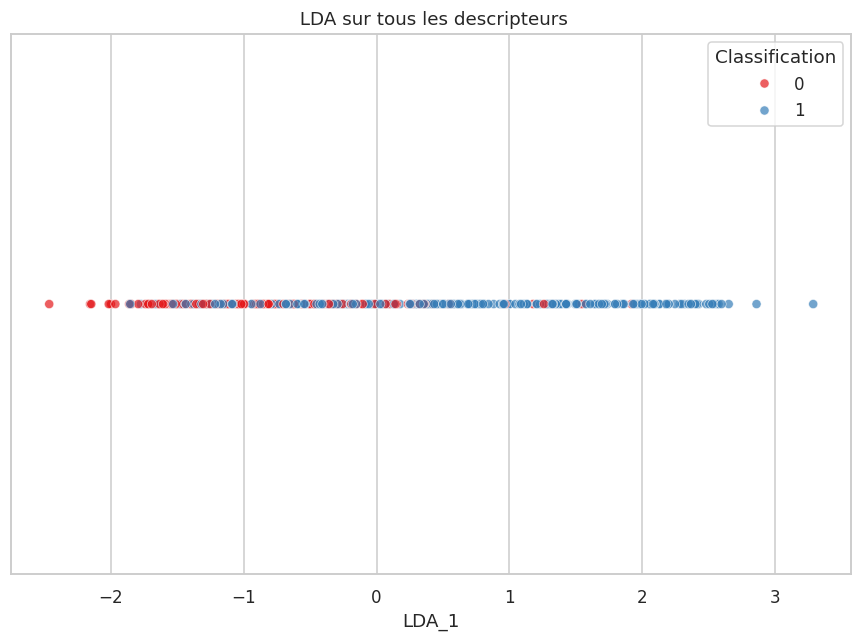

In [5]:
plt.figure(figsize=(8, 6))
if n_components == 1:
    sns.scatterplot(
        data=df_lda, x='LDA_1', y=np.zeros(len(df_lda)),
        hue='Classification', palette='Set1', alpha=0.7
    )
    plt.ylabel('')
    plt.yticks([])
else:
    sns.scatterplot(
        data=df_lda, x='LDA_1', y='LDA_2',
        hue='Classification', palette='Set1', alpha=0.7
    )
plt.title(' LDA sur tous les descripteurs')
plt.tight_layout()
plt.show()

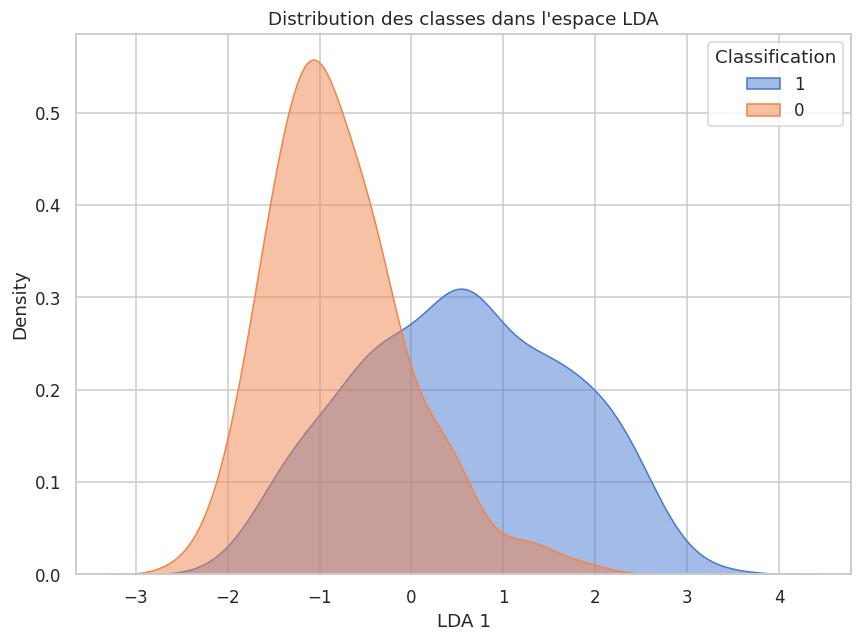

In [6]:
plt.figure(figsize=(8, 6))
if n_components == 1:
    for cls in df_lda['Classification'].unique():
        sns.kdeplot(df_lda[df_lda['Classification'] == cls]['LDA_1'], label=cls, fill=True, alpha=0.5)
    plt.xlabel('LDA 1')
else:
    for cls in df_lda['Classification'].unique():
        sns.kdeplot(
            x=df_lda[df_lda['Classification'] == cls]['LDA_1'],
            y=df_lda[df_lda['Classification'] == cls]['LDA_2'],
            label=cls,
            fill=True,
            alpha=0.5
        )
    plt.xlabel('LDA 1')
    plt.ylabel('LDA 2')
plt.title('Distribution des classes dans l\'espace LDA')
plt.legend(title='Classification')
plt.tight_layout()
plt.show()

In [7]:
coef_df = pd.DataFrame(lda.coef_, columns=X_all.columns).T
coef_df['max_abs_coef'] = coef_df.abs().max(axis=1)
coef_df_sorted = coef_df.sort_values('max_abs_coef', ascending=False)

print('Tableau des 10 meilleurs coefficients de la LDA :')
coef_df_sorted.head(10)

Tableau des 10 meilleurs coefficients de la LDA :


,0,max_abs_coef
Ka,1.161781,1.161781
TE_Density_Asymmetry,-1.149021,1.149021
TE_Coverage_Mean,-0.868582,0.868582
TE_Density_Mean,0.770585,0.770585
TE_Number_Asymmetry,0.555377,0.555377
TE_Coverage_Asymmetry,0.433027,0.433027
PPI_Jaccard,-0.391012,0.391012
TE_Number_Mean,0.292995,0.292995
PPI_Interactant_Mean,0.278637,0.278637
PPI_Union,0.263000,0.263000


## K-means sur les cinq meilleurs descripteurs

In [8]:
k_values = [2, 3, 4, 5, 7, 9, 10]

X_train = pd.read_csv("Données/X_train_clean.csv")

selected_descriptors = [
    "Ka",
    "TE_Density_Asymmetry",
    "TE_Coverage_Asymmetry",
    "TE_Number_Asymmetry",
    "PPI_Jaccard",
]

missing_descriptors = [
    column for column in selected_descriptors
    if column not in X_train.columns
]

if missing_descriptors:
    raise KeyError(f"Descripteurs absents : {missing_descriptors}")

### Préparation des clusters 0

Pour un descripteur _Asymmetry, le cluster 0 contient uniquement les lignes vérifiant simultanément :
Asymmetry == 0
Mean == 0

In [9]:
def prepare_descriptor_data(data, descriptor):
    values = pd.to_numeric(data[descriptor], errors="coerce")

    fixed_zero_mask = pd.Series(False, index=data.index)
    mean_descriptor = None

    if descriptor.endswith("_Asymmetry"):
        mean_descriptor = descriptor.replace("_Asymmetry", "_Mean")

        if mean_descriptor not in data.columns:
            raise KeyError(f"Colonne absente : {mean_descriptor}")

        mean_values = pd.to_numeric(
            data[mean_descriptor],
            errors="coerce"
        )

        fixed_zero_mask = (
            values.eq(0)
            & mean_values.eq(0)
        )

    valid_mask = values.notna()
    kmeans_mask = valid_mask & ~fixed_zero_mask

    return {
        "values": values,
        "fixed_zero_mask": fixed_zero_mask,
        "valid_mask": valid_mask,
        "kmeans_mask": kmeans_mask,
        "mean_descriptor": mean_descriptor,
    }

In [15]:
# voir le nombre de valeurs =0 pour _Asymmetry et _Mean
for descriptor in selected_descriptors:
    data = prepare_descriptor_data(X_train, descriptor)
    fixed_zero_count = data["fixed_zero_mask"].sum()
    valid_count = data["valid_mask"].sum()
    kmeans_count = data["kmeans_mask"].sum()

    print(f"Descripteur : {descriptor}")
    print(f"  Valeurs valides : {valid_count}")
    print(f"  Valeurs fixes à zéro : {fixed_zero_count}")
    print(f"  Valeurs pour KMeans : {kmeans_count}")

Descripteur : Ka
  Valeurs valides : 444
  Valeurs fixes à zéro : 0
  Valeurs pour KMeans : 444
Descripteur : TE_Density_Asymmetry
  Valeurs valides : 444
  Valeurs fixes à zéro : 139
  Valeurs pour KMeans : 305
Descripteur : TE_Coverage_Asymmetry
  Valeurs valides : 444
  Valeurs fixes à zéro : 139
  Valeurs pour KMeans : 305
Descripteur : TE_Number_Asymmetry
  Valeurs valides : 444
  Valeurs fixes à zéro : 139
  Valeurs pour KMeans : 305
Descripteur : PPI_Jaccard
  Valeurs valides : 444
  Valeurs fixes à zéro : 0
  Valeurs pour KMeans : 444


### Evaluation valeurs k

In [10]:
def evaluate_descriptor(data, descriptor, k_values):
    prepared = prepare_descriptor_data(data, descriptor)

    values = prepared["values"]
    fixed_zero_mask = prepared["fixed_zero_mask"]
    valid_mask = prepared["valid_mask"]
    kmeans_mask = prepared["kmeans_mask"]

    n_fixed_clusters = int(fixed_zero_mask.any())
    n_unique_kmeans_values = values.loc[kmeans_mask].nunique()

    results = []

    for k in k_values:
        kmeans_k = k - n_fixed_clusters

        if kmeans_k < 1:
            continue

        if n_unique_kmeans_values < kmeans_k:
            print(
                f"{descriptor}, k={k} ignoré : "
                f"{n_unique_kmeans_values} valeurs distinctes disponibles."
            )
            continue

        values_for_kmeans = values.loc[kmeans_mask].to_numpy().reshape(-1, 1)

        scaler = StandardScaler()
        values_scaled = scaler.fit_transform(values_for_kmeans)

        model = KMeans(
            n_clusters=kmeans_k,
            n_init=n_init,
            random_state=random_state,
            init="k-means++",
        )

        labels_kmeans = model.fit_predict(values_scaled)

        labels = pd.Series(
            index=data.index,
            dtype="Int64"
        )

        if n_fixed_clusters:
            labels.loc[fixed_zero_mask] = 0
            labels.loc[kmeans_mask] = labels_kmeans + 1
        else:
            labels.loc[kmeans_mask] = labels_kmeans

        evaluation_mask = valid_mask & labels.notna()

        X_evaluation = values.loc[evaluation_mask].to_numpy().reshape(-1, 1)
        labels_evaluation = labels.loc[evaluation_mask].astype(int).to_numpy()

        n_observed_clusters = len(np.unique(labels_evaluation))

        if n_observed_clusters > 1:
            silhouette = silhouette_score(
                X_evaluation,
                labels_evaluation
            )
            davies_bouldin = davies_bouldin_score(
                X_evaluation,
                labels_evaluation
            )
            calinski_harabasz = calinski_harabasz_score(
                X_evaluation,
                labels_evaluation
            )
        else:
            silhouette = np.nan
            davies_bouldin = np.nan
            calinski_harabasz = np.nan

        cluster_sizes = labels.loc[evaluation_mask].value_counts()

        results.append({
            "Descripteur": descriptor,
            "k": k,
            "k_KMeans": kmeans_k,
            "Inertie": model.inertia_,
            "Silhouette": silhouette,
            "Davies_Bouldin": davies_bouldin,
            "Calinski_Harabasz": calinski_harabasz,
            "Taille_min": int(cluster_sizes.min()),
            "Taille_max": int(cluster_sizes.max()),
            "Taille_cluster_zero": int(fixed_zero_mask.sum()),
            "Labels": labels,
            "Modele": model,
            "Scaler": scaler,
        })

    return results

In [11]:
all_results = {}

for descriptor in selected_descriptors:
    all_results[descriptor] = evaluate_descriptor(
        X_train,
        descriptor,
        k_values
    )

results_df = pd.DataFrame([
    {
        key: value
        for key, value in result.items()
        if key not in {"Labels", "Modele", "Scaler"}
    }
    for descriptor_results in all_results.values()
    for result in descriptor_results
])

display(results_df)

,Descripteur,k,k_KMeans,Inertie,Silhouette,Davies_Bouldin,Calinski_Harabasz,Taille_min,Taille_max,Taille_cluster_zero
0,Ka,2,2,116.265396,0.650850,0.507505,1245.931289,138,306,0
1,Ka,3,3,44.814539,0.640531,0.452858,1964.103506,81,230,0
2,Ka,4,4,27.302563,0.601431,0.491369,2238.457383,73,174,0
3,Ka,5,5,18.324654,0.584779,0.518006,2549.454376,41,174,0
4,Ka,7,7,9.611898,0.557657,0.518139,3291.538472,33,119,0
5,Ka,9,9,5.816776,0.555332,0.522653,4096.119893,11,96,0
6,Ka,10,10,4.889703,0.557220,0.484287,4330.503376,4,104,0
7,TE_Density_Asymmetry,2,1,305.000000,0.358920,0.579003,220.548283,139,305,139
8,TE_Density_Asymmetry,3,2,111.477432,0.498083,0.518032,683.808766,43,262,139
9,TE_Density_Asymmetry,4,3,48.679631,0.618054,0.469305,1230.794135,28,168,139


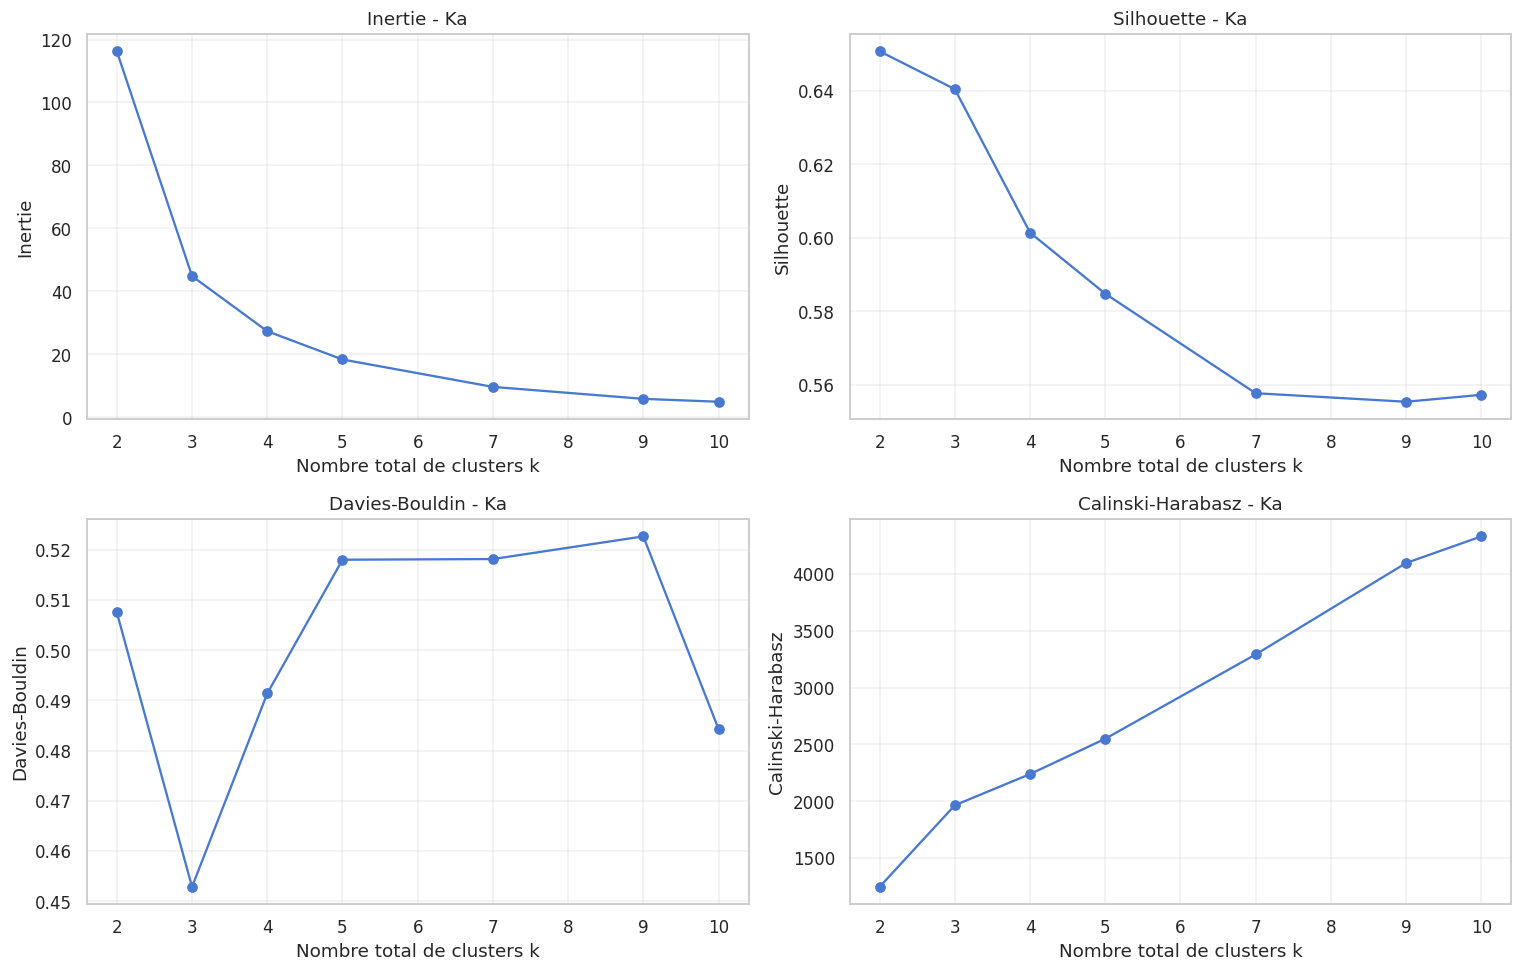

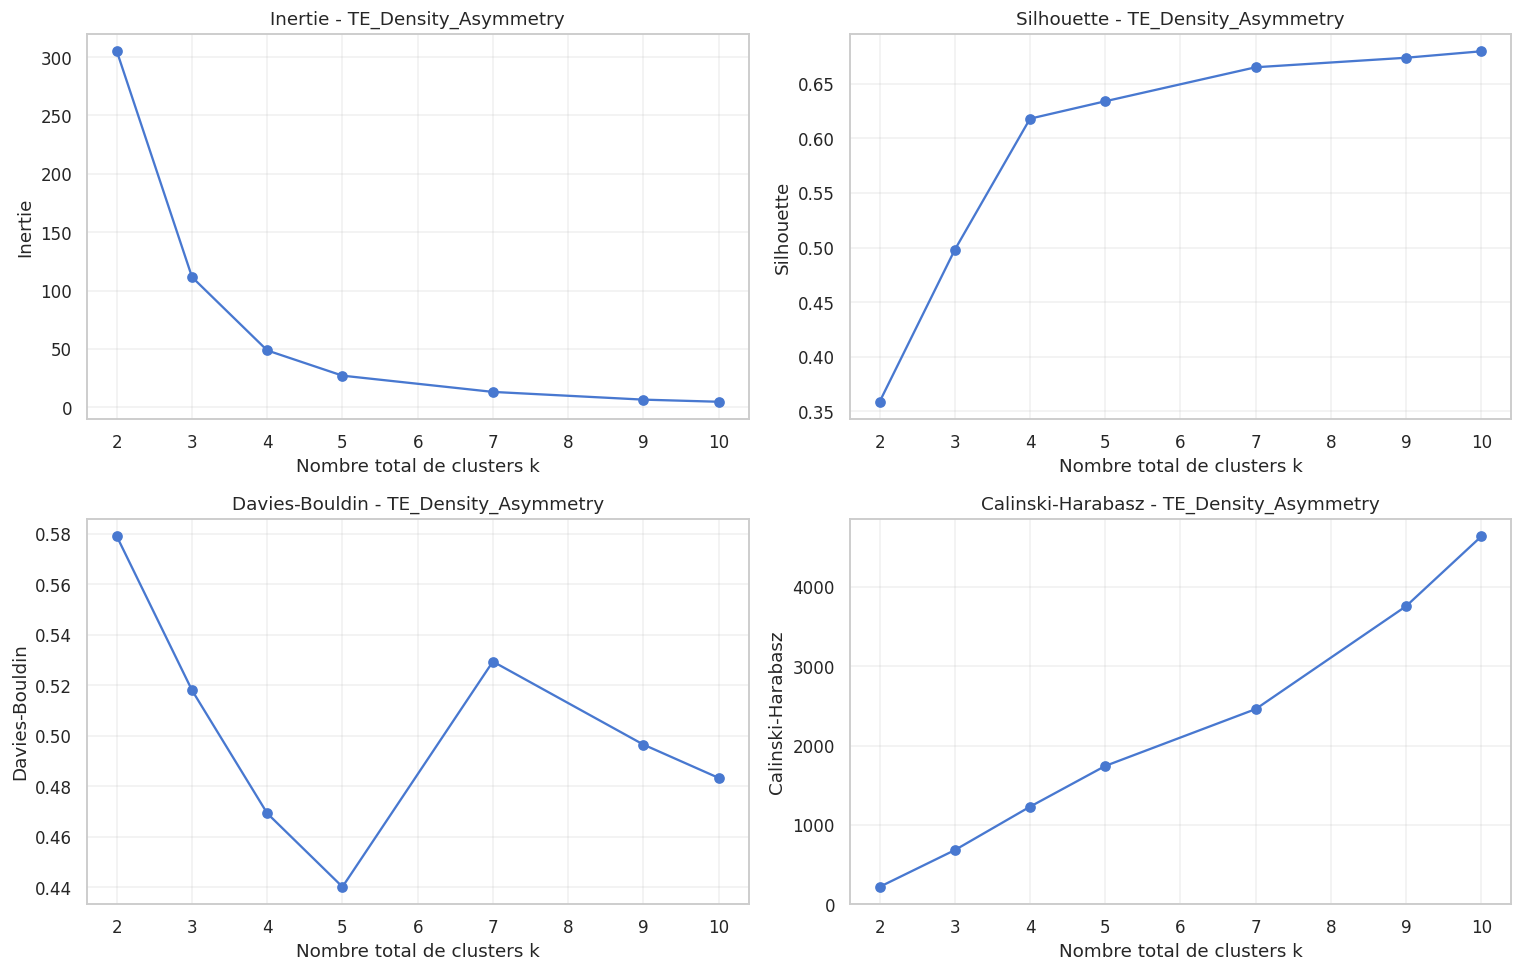

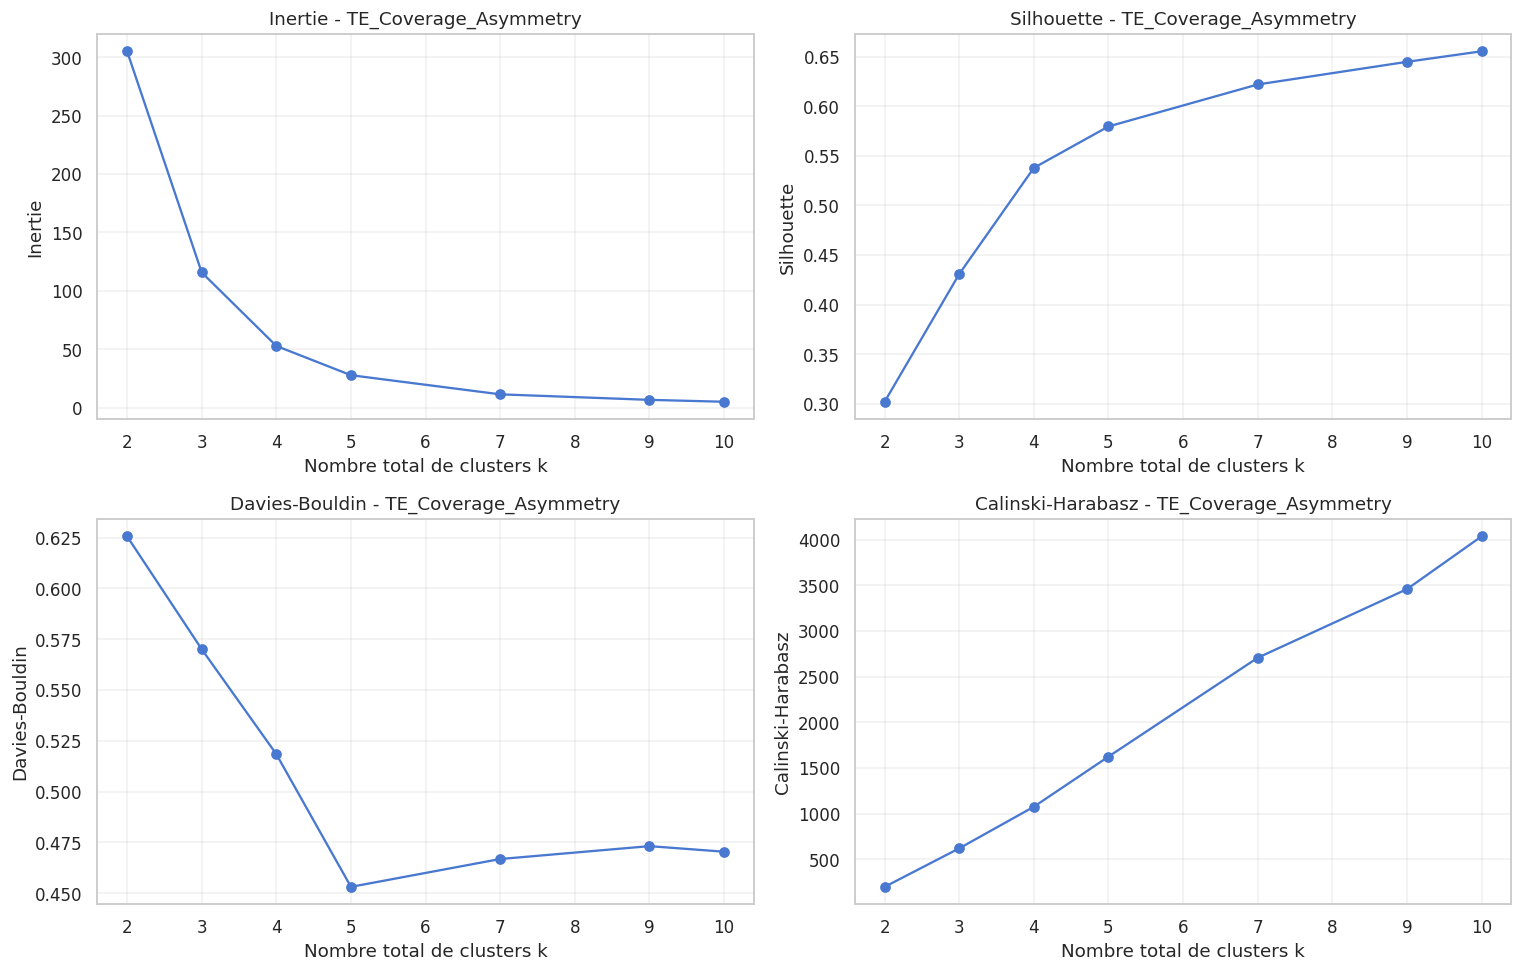

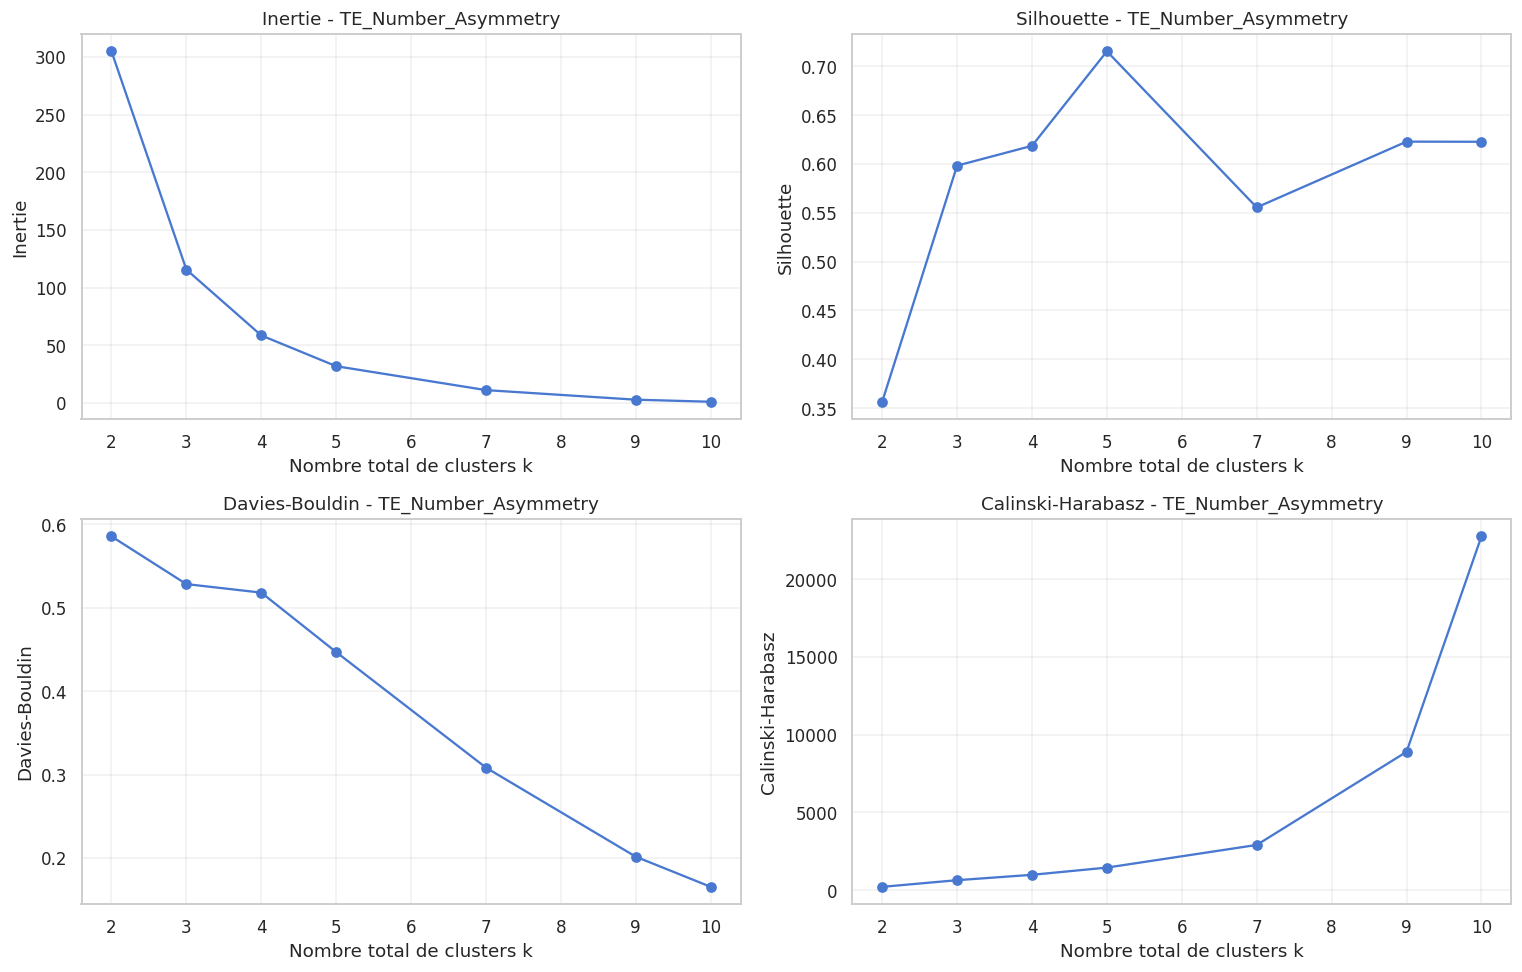

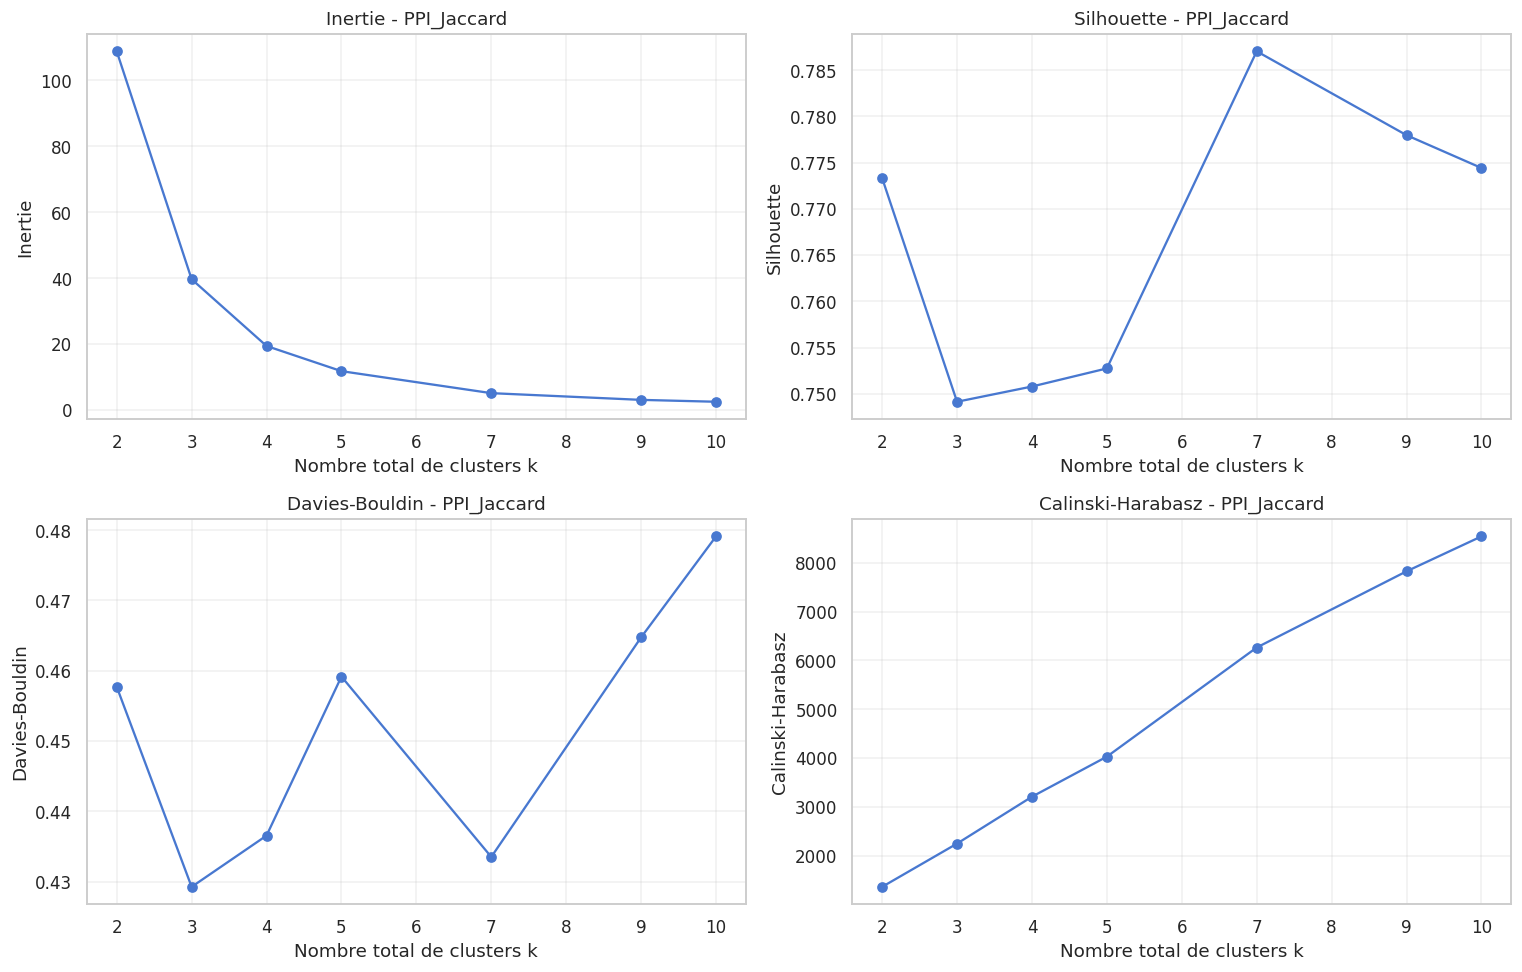

In [12]:
metrics_to_plot = [
    ("Inertie", "Inertie"),
    ("Silhouette", "Silhouette"),
    ("Davies_Bouldin", "Davies-Bouldin"),
    ("Calinski_Harabasz", "Calinski-Harabasz"),
]

for descriptor in selected_descriptors:
    descriptor_df = results_df[
        results_df["Descripteur"] == descriptor
    ].sort_values("k")

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    axes = axes.ravel()

    for axis, (column, title) in zip(axes, metrics_to_plot):
        axis.plot(
            descriptor_df["k"],
            descriptor_df[column],
            marker="o"
        )
        axis.set_title(f"{title} - {descriptor}")
        axis.set_xlabel("Nombre total de clusters k")
        axis.set_ylabel(title)
        axis.grid(alpha=0.3)

    fig.tight_layout()
    plt.show()

### Classement valeurs k

In [13]:
def rank_k_values(descriptor_df):
    ranked = descriptor_df.copy()

    ranked["Rang_Silhouette"] = (
        ranked["Silhouette"]
        .rank(ascending=False, method="min")
    )

    ranked["Rang_Davies_Bouldin"] = (
        ranked["Davies_Bouldin"]
        .rank(ascending=True, method="min")
    )

    ranked["Rang_Calinski_Harabasz"] = (
        ranked["Calinski_Harabasz"]
        .rank(ascending=False, method="min")
    )

    ranked["Score_global"] = (
        ranked["Rang_Silhouette"]
        + ranked["Rang_Davies_Bouldin"]
        + ranked["Rang_Calinski_Harabasz"]
    )

    return ranked.sort_values(
        ["Score_global", "Silhouette"],
        ascending=[True, False]
    )


best_k_by_descriptor = {}

for descriptor in selected_descriptors:
    descriptor_df = results_df[
        results_df["Descripteur"] == descriptor
    ]

    ranking = rank_k_values(descriptor_df)
    best_k = int(ranking.iloc[0]["k"])

    best_k_by_descriptor[descriptor] = best_k

    print(f"\n{descriptor}")
    display(ranking[
        [
            "k",
            "Inertie",
            "Silhouette",
            "Davies_Bouldin",
            "Calinski_Harabasz",
            "Taille_min",
            "Taille_max",
            "Taille_cluster_zero",
            "Score_global",
        ]
    ])
    print(f"Meilleur compromis proposé : k = {best_k}")


Ka


,k,Inertie,Silhouette,Davies_Bouldin,Calinski_Harabasz,Taille_min,Taille_max,Taille_cluster_zero,Score_global
1,3,44.814539,0.640531,0.452858,1964.103506,81,230,0,9.0
6,10,4.889703,0.557220,0.484287,4330.503376,4,104,0,9.0
2,4,27.302563,0.601431,0.491369,2238.457383,73,174,0,11.0
0,2,116.265396,0.650850,0.507505,1245.931289,138,306,0,12.0
3,5,18.324654,0.584779,0.518006,2549.454376,41,174,0,13.0
4,7,9.611898,0.557657,0.518139,3291.538472,33,119,0,14.0
5,9,5.816776,0.555332,0.522653,4096.119893,11,96,0,16.0


Meilleur compromis proposé : k = 3

TE_Density_Asymmetry


,k,Inertie,Silhouette,Davies_Bouldin,Calinski_Harabasz,Taille_min,Taille_max,Taille_cluster_zero,Score_global
13,10,4.706008,0.679733,0.483376,4636.562959,3,139,139,5.0
12,9,6.521986,0.673831,0.496570,3757.287940,3,139,139,8.0
10,5,27.065713,0.633988,0.440209,1744.123802,13,156,139,9.0
11,7,13.143574,0.665115,0.529434,2460.613663,13,139,139,12.0
9,4,48.679631,0.618054,0.469305,1230.794135,28,168,139,12.0
8,3,111.477432,0.498083,0.518032,683.808766,43,262,139,17.0
7,2,305.000000,0.358920,0.579003,220.548283,139,305,139,21.0


Meilleur compromis proposé : k = 10

TE_Coverage_Asymmetry


...

Meilleur compromis proposé : k = 10

TE_Number_Asymmetry


,k,Inertie,Silhouette,Davies_Bouldin,Calinski_Harabasz,Taille_min,Taille_max,Taille_cluster_zero,Score_global
27,10,0.957181,0.622823,0.165519,22749.755351,1,139,139,5.0
26,9,2.749350,0.622970,0.201628,8895.407095,4,139,139,6.0
24,5,31.806255,0.715502,0.446837,1451.725794,4,139,139,9.0
25,7,11.055353,0.555598,0.308340,2908.433399,4,139,139,12.0
23,4,58.510837,0.618683,0.518060,987.660620,15,211,139,14.0
22,3,115.620844,0.598371,0.528281,642.509797,94,211,139,17.0
21,2,305.000000,0.356523,0.585441,213.791369,139,305,139,21.0


Meilleur compromis proposé : k = 10

PPI_Jaccard


,k,Inertie,Silhouette,Davies_Bouldin,Calinski_Harabasz,Taille_min,Taille_max,Taille_cluster_zero,Score_global
32,7,5.103433,0.787043,0.433518,6263.685167,14,242,0,6.0
33,9,3.064009,0.777970,0.464759,7825.008840,10,241,0,10.0
34,10,2.492825,0.774421,0.479120,8540.692984,10,238,0,11.0
31,5,11.776357,0.752741,0.459177,4028.116926,27,256,0,14.0
30,4,19.416252,0.750784,0.436555,3207.224783,30,285,0,14.0
29,3,39.678026,0.749136,0.429265,2246.911029,38,309,0,14.0
28,2,108.854900,0.773327,0.457728,1360.840288,68,376,0,15.0


Meilleur compromis proposé : k = 7


### Récupération labels meilleur k

In [14]:
best_labels_by_descriptor = {}

for descriptor, best_k in best_k_by_descriptor.items():
    descriptor_results = all_results[descriptor]

    selected_result = next(
        result
        for result in descriptor_results
        if result["k"] == best_k
    )

    best_labels_by_descriptor[descriptor] = selected_result["Labels"]

    X_train[f"{descriptor}_cluster"] = (
        selected_result["Labels"]
    )

display(
    X_train[
        selected_descriptors
        + [f"{descriptor}_cluster" for descriptor in selected_descriptors]
    ].head()
)

,Ka,TE_Density_Asymmetry,TE_Coverage_Asymmetry,TE_Number_Asymmetry,PPI_Jaccard,Ka_cluster,TE_Density_Asymmetry_cluster,TE_Coverage_Asymmetry_cluster,TE_Number_Asymmetry_cluster,PPI_Jaccard_cluster
0,0.4049,0.022341,4.458466,0.0,11.111111,0,7,7,7,3
1,0.4109,0.402678,28.027854,2.0,7.142857,0,1,2,4,3
2,0.5092,0.000000,0.000000,0.0,37.500000,0,0,0,0,2
3,0.3528,0.182388,15.273775,1.0,7.142857,0,5,3,1,3
4,0.4092,0.182388,15.273775,1.0,0.000000,0,5,3,1,0


In [8]:
selected_descriptors = [
    'Ka',
    'TE_Density_Asymmetry',
    'TE_Coverage_Asymmetry',
    'TE_Number_Asymmetry',
    'PPI_Jaccard'
]

missing_descriptors = [
    column for column in selected_descriptors
    if column not in X_train.columns
]
if missing_descriptors:
    raise KeyError(f'Descripteurs absents : {missing_descriptors}')

asymmetry_descriptors = [
    column for column in selected_descriptors
    if column.endswith('_Asymmetry')
]
mean_descriptors = {
    column: column.replace('_Asymmetry', '_Mean')
    for column in asymmetry_descriptors
}

n_clusters_zero = 2
n_clusters_nonzero = 3
labels_by_descriptor = {}
kmeans_results = {}

for descriptor in selected_descriptors:
    values = pd.to_numeric(X_train[descriptor], errors='coerce')
    labels_full = pd.Series(index=X_train.index, dtype='Int64')

    if descriptor in asymmetry_descriptors:
        mean_descriptor = mean_descriptors[descriptor]
        if mean_descriptor not in X_train.columns:
            raise KeyError(f'Colonne absente : {mean_descriptor}')

        zero_mask = values.eq(0)
        nonzero_mask = values.notna() & values.ne(0)
        zero_mean = pd.to_numeric(
            X_train.loc[zero_mask, mean_descriptor], errors='coerce'
        ).dropna()

        if len(zero_mean) >= 2 and zero_mean.nunique() >= 2:
            zero_k = min(n_clusters_zero, zero_mean.nunique())
            zero_model = KMeans(
                n_clusters=zero_k, n_init=n_init, random_state=random_state
            )
            zero_labels = zero_model.fit_predict(
                zero_mean.to_numpy().reshape(-1, 1)
            )
            labels_full.loc[zero_mean.index] = zero_labels
            zero_cluster_count = int(zero_labels.max()) + 1
        else:
            zero_model = None
            labels_full.loc[zero_mask] = 0
            zero_cluster_count = 1
    else:
        zero_mask = pd.Series(False, index=X_train.index)
        nonzero_mask = values.notna()
        zero_model = None
        zero_cluster_count = 0

    values_nonzero = values.loc[nonzero_mask].dropna()
    X_descriptor = values_nonzero.to_numpy().reshape(-1, 1)
    scaler = StandardScaler()
    X_descriptor_scaled = scaler.fit_transform(X_descriptor)

    nonzero_model = KMeans(
        n_clusters=n_clusters_nonzero,
        n_init=n_init,
        random_state=random_state
    )
    nonzero_labels = nonzero_model.fit_predict(X_descriptor_scaled)
    labels_full.loc[values_nonzero.index] = nonzero_labels + zero_cluster_count
    labels_full = labels_full.astype('Int64')

    labels_by_descriptor[descriptor] = labels_full
    kmeans_results[descriptor] = {
        'zero_model': zero_model,
        'nonzero_model': nonzero_model,
        'scaler': scaler,
        'labels_full': labels_full,
        'labels_nonzero': nonzero_labels,
        'n_zero': int(zero_mask.sum()),
        'n_nonzero': int(len(values_nonzero))
    }

    print(
        f'{descriptor}: {int(zero_mask.sum())} valeurs nulles, '
        f'{len(values_nonzero)} valeurs non nulles'
    )

Ka: 0 valeurs nulles, 444 valeurs non nulles
TE_Density_Asymmetry: 139 valeurs nulles, 305 valeurs non nulles
TE_Coverage_Asymmetry: 139 valeurs nulles, 305 valeurs non nulles
TE_Number_Asymmetry: 162 valeurs nulles, 282 valeurs non nulles
PPI_Jaccard: 0 valeurs nulles, 444 valeurs non nulles


In [9]:
# Donnees standardisees des cinq descripteurs
X_top_5 = X_train[selected_descriptors].copy()
scaler_top_5 = StandardScaler()
X_top_5_scaled = pd.DataFrame(
    scaler_top_5.fit_transform(X_top_5),
    columns=selected_descriptors,
    index=X_top_5.index
)

# Tableau de synthese des tailles de clusters
cluster_size_rows = []
for descriptor, labels in labels_by_descriptor.items():
    counts = labels.value_counts().sort_index()
    for cluster, size in counts.items():
        cluster_size_rows.append({
            'Descripteur': descriptor,
            'Cluster': int(cluster),
            'Taille': int(size)
        })

cluster_sizes_df = pd.DataFrame(cluster_size_rows)
display(cluster_sizes_df)

,Descripteur,Cluster,Taille
0,Ka,0,133
1,Ka,1,81
2,Ka,2,230
3,TE_Density_Asymmetry,0,139
4,TE_Density_Asymmetry,1,168
5,TE_Density_Asymmetry,2,28
6,TE_Density_Asymmetry,3,109
7,TE_Coverage_Asymmetry,0,139
8,TE_Coverage_Asymmetry,1,171
9,TE_Coverage_Asymmetry,2,20
